In [1]:
# ============================================================
# 1. IMPORTS AND PROJECT PATHS
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name.lower() in {"notebook", "notebooks"}:
    PROJECT_DIR = PROJECT_DIR.parent

OUTPUT_DIR = PROJECT_DIR / "outputs" / "final_project_synthesis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Output directory:", OUTPUT_DIR)

Project directory: c:\Users\devra\Music\gas-turbine-ml
Output directory: c:\Users\devra\Music\gas-turbine-ml\outputs\final_project_synthesis


In [2]:
# ============================================================
# 2. LOAD MODEL COMPARISON RESULTS
# ============================================================

comparison_candidates = [
    PROJECT_DIR / "all_models_comparison.csv",
    PROJECT_DIR / "outputs" / "all_models_comparison.csv",
    PROJECT_DIR / "all_models_comparison(1).csv",
    PROJECT_DIR / "outputs" / "all_models_comparison(1).csv",
]

comparison_path = next((p for p in comparison_candidates if p.exists()), None)

if comparison_path is None:
    raise FileNotFoundError(
        "Could not find all_models_comparison.csv. "
        "Place the model comparison CSV in the project root or outputs folder."
    )

model_comparison = pd.read_csv(comparison_path)
model_comparison["Target"] = model_comparison["Target"].astype(str).str.upper()

selected_models = {
    "TEY": "Random Forest",
    "CO": "Gradient Boosting",
    "NOX": "Linear Regression",
}

selected_rows = []
for target, model_name in selected_models.items():
    match = model_comparison[
        (model_comparison["Target"] == target) &
        (model_comparison["Model"] == model_name)
    ]
    if match.empty:
        raise ValueError(f"Missing comparison result for {target}: {model_name}")
    selected_rows.append(match.iloc[0])

selected_model_results = pd.DataFrame(selected_rows).reset_index(drop=True)

print("Loaded comparison:", comparison_path)
display(model_comparison)
print("\nSelected model results:")
display(selected_model_results)

Loaded comparison: c:\Users\devra\Music\gas-turbine-ml\outputs\all_models_comparison.csv


,Model,Target,MAE,RMSE,R2
0,Mean Predictor,TEY,12.945258,16.189590,-0.001419
1,Mean Predictor,CO,1.391866,2.427608,-0.179982
2,Mean Predictor,NOX,11.114354,13.024475,-0.368979
3,Linear Regression,TEY,1.283053,1.790959,0.987745
4,Linear Regression,CO,1.367043,1.924115,0.258723
5,Linear Regression,NOX,8.181042,10.214565,0.157992
6,Ridge Regression,TEY,1.462708,2.029570,0.984262
7,Ridge Regression,CO,1.338801,1.888141,0.286183
8,Ridge Regression,NOX,8.240273,10.273100,0.148314
9,Random Forest,TEY,0.858715,1.144135,0.994999



Selected model results:


,Model,Target,MAE,RMSE,R2
0,Random Forest,TEY,0.858715,1.144135,0.994999
1,Gradient Boosting,CO,0.924309,1.508896,0.544134
2,Linear Regression,NOX,8.181042,10.214565,0.157992


In [3]:
# ============================================================
# 3. FINAL MODEL PERFORMANCE SUMMARY
# ============================================================

metric_cols = ["MAE", "RMSE", "R2"]
performance_summary = selected_model_results[
    ["Target", "Model"] + metric_cols
].copy()

performance_summary = performance_summary.rename(columns={
    "Target": "Prediction target",
    "Model": "Selected model",
    "R2": "R-squared"
})

performance_summary.to_csv(
    OUTPUT_DIR / "final_selected_model_performance.csv", index=False
)

display(performance_summary)

,Prediction target,Selected model,MAE,RMSE,R-squared
0,TEY,Random Forest,0.858715,1.144135,0.994999
1,CO,Gradient Boosting,0.924309,1.508896,0.544134
2,NOX,Linear Regression,8.181042,10.214565,0.157992


In [4]:
# ============================================================
# 4. LOAD NOX DIAGNOSTIC RESULTS
# ============================================================

def find_file(filename):
    candidates = [
        PROJECT_DIR / filename,
        PROJECT_DIR / "outputs" / filename,
        PROJECT_DIR / "outputs" / "nox_residual_feature_shift" / filename,
        PROJECT_DIR / "outputs" / "nox_residual_and_feature_shift" / filename,
    ]
    return next((p for p in candidates if p.exists()), None)

shift_path = find_file("feature_distribution_shift.csv")
yearly_path = find_file("yearly_feature_nox_summary.csv")
residual_path = find_file("linear_regression_2015_residual_metrics.csv")

if shift_path:
    feature_shift = pd.read_csv(shift_path)
    display(feature_shift)
else:
    feature_shift = pd.DataFrame()
    print("Feature-shift CSV not found; skipping its detailed table.")

if yearly_path:
    yearly_nox_raw = pd.read_csv(yearly_path, header=None)
    display(yearly_nox_raw)
else:
    yearly_nox_raw = pd.DataFrame()
    print("Yearly NOX summary CSV not found.")

if residual_path:
    residual_metrics = pd.read_csv(residual_path)
    display(residual_metrics)
else:
    residual_metrics = pd.DataFrame()
    print("Residual metrics CSV not found; skipping its detailed table.")

,Variable,Early_Mean_2011_2013,Later_Mean_2014_2015,Mean_Change,Standardized_Mean_Difference,KS_Statistic,KS_pvalue
0,NOX,68.776529,59.977327,-8.799202,-0.814056,0.398117,0.000000e+00
1,TIT,1083.080280,1078.906842,-4.173438,-0.237587,0.313785,0.000000e+00
2,AFDP,4.037750,3.754252,-0.283498,-0.378976,0.186704,1.458942e-268
3,AH,79.555224,75.290819,-4.264405,-0.295881,0.157874,1.013766e-191
4,TAT,545.520170,547.132631,1.612461,0.246707,0.120863,2.737998e-112
5,GTEP,25.317873,25.939087,0.621215,0.148902,0.096682,6.315248e-72
6,CDP,12.060208,12.061010,0.000802,0.000741,0.080503,5.695946e-50
7,AP,1012.812607,1013.463197,0.650590,0.100539,0.039294,3.190821e-12
8,AT,17.712247,17.713458,0.001211,0.000162,0.021091,7.950058e-04


,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
0,NaN,AT,AT,AT,AP,AP,AP,AH,AH,AH,...,TIT,TAT,TAT,TAT,CDP,CDP,CDP,NOX,NOX,NOX
1,NaN,mean,std,median,mean,std,median,mean,std,median,...,median,mean,std,median,mean,std,median,mean,std,median
2,Year,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2011,17.112261395223317,7.428306830541006,16.366,1014.1678828768047,6.293003259542002,1013.6,79.17498893536634,13.465898217173944,82.129,...,1088.0,544.5031696127379,8.288471004058916,549.86,12.207577830252328,1.1465607326632246,12.008,67.57539198488733,10.683331413906624,65.542
4,2012,18.397949938384897,7.661037968045689,19.1205,1012.258152857892,6.384291103597349,1012.0,79.07480414263242,14.105087083042662,82.4115,...,1089.1,546.2637926061877,7.331344862156148,549.92,12.000121080230729,1.0493842268164073,12.041,68.78896512847405,10.224936920542437,67.2465
5,2013,17.602619720357943,6.862889635965992,17.2045,1011.9996071029084,6.290064834294927,1011.8,80.4616240212528,14.125390428542994,84.002,...,1087.3,545.7808850671141,7.358934768008718,549.9,11.971586311521254,1.1321586188044093,11.956,70.00789890939598,12.048248925943629,68.65100000000001
6,2014,18.21707059234423,6.994920191069386,18.284,1012.3842609667505,5.973394632173102,1012.0,82.1439258172674,13.000423843455598,84.6565,...,1079.2,547.6382537021515,4.611472274278124,549.91,12.023857404302877,0.9483522691326011,11.909,60.06688586197262,9.971729479709571,59.2785
7,2015,17.225259291170097,8.095783332850193,17.4565,1014.5091102383532,6.8954301329730034,1014.0,68.64746411159263,13.541116395037719,70.952,...,1080.3,546.6424837486458,5.4890662286815655,549.72,12.09702474268689,1.136600536693579,11.933,59.89050947995666,11.132463621891869,56.838499999999996


,Model,MAE,RMSE,R2
0,Linear Regression,8.181042,10.214565,0.157992


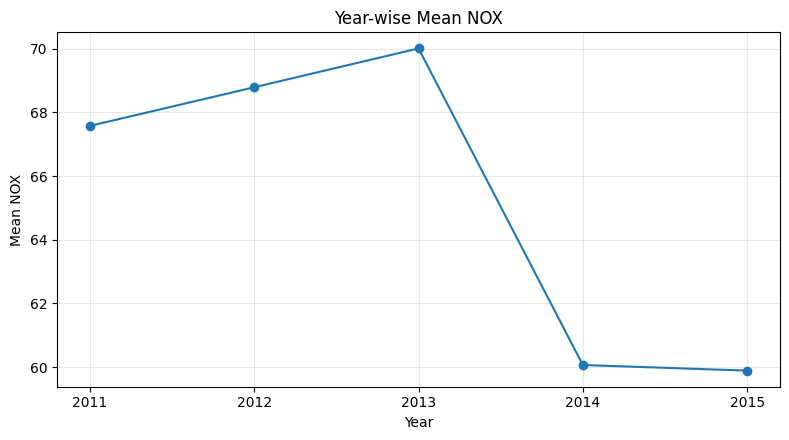

,Year,Mean_NOX
0,2011,67.575392
1,2012,68.788965
2,2013,70.007899
3,2014,60.066886
4,2015,59.890509


In [5]:
# ============================================================
# 5. NOX YEARLY TREND
# ============================================================

yearly_nox = pd.DataFrame({
    "Year": [2011, 2012, 2013, 2014, 2015],
    "Mean_NOX": [67.5753919849, 68.7889651285, 70.0078989094,
                 60.0668858620, 59.8905094800]
})

plt.figure(figsize=(8, 4.5))
plt.plot(yearly_nox["Year"], yearly_nox["Mean_NOX"], marker="o")
plt.xticks(yearly_nox["Year"])
plt.xlabel("Year")
plt.ylabel("Mean NOX")
plt.title("Year-wise Mean NOX")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "yearly_mean_nox.png", dpi=200)
plt.show()

yearly_nox.to_csv(OUTPUT_DIR / "yearly_mean_nox.csv", index=False)
display(yearly_nox)

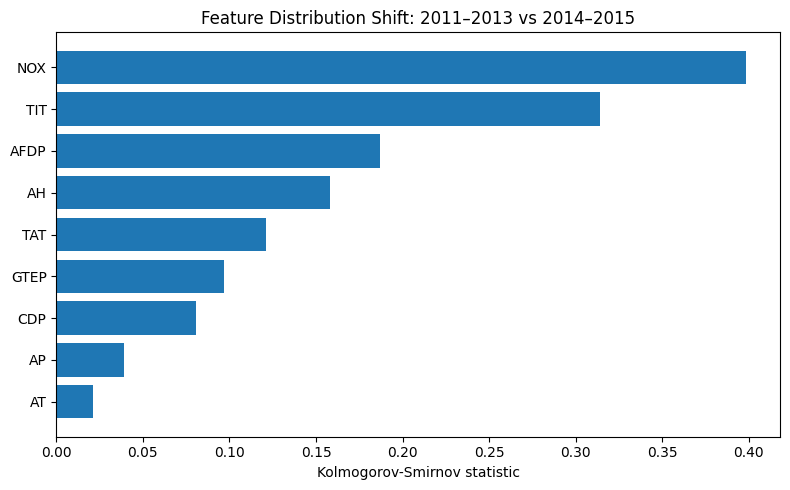

,Variable,Early_Mean_2011_2013,Later_Mean_2014_2015,Mean_Change,Standardized_Mean_Difference,KS_Statistic
0,NOX,68.776529,59.977327,-8.799202,-0.814056,0.398117
1,TIT,1083.080280,1078.906842,-4.173438,-0.237587,0.313785
2,AFDP,4.037750,3.754252,-0.283498,-0.378976,0.186704
3,AH,79.555224,75.290819,-4.264405,-0.295881,0.157874
4,TAT,545.520170,547.132631,1.612461,0.246707,0.120863
5,GTEP,25.317873,25.939087,0.621215,0.148902,0.096682
6,CDP,12.060208,12.061010,0.000802,0.000741,0.080503
7,AP,1012.812607,1013.463197,0.650590,0.100539,0.039294
8,AT,17.712247,17.713458,0.001211,0.000162,0.021091


In [6]:
# ============================================================
# 6. NOX FEATURE SHIFT SUMMARY
# ============================================================

if not feature_shift.empty:
    shift_columns = [
        col for col in [
            "Variable", "Early_Mean_2011_2013",
            "Later_Mean_2014_2015", "Mean_Change",
            "Standardized_Mean_Difference", "KS_Statistic"
        ] if col in feature_shift.columns
    ]
    shift_summary = feature_shift[shift_columns].copy()
    shift_summary.to_csv(OUTPUT_DIR / "nox_feature_shift_summary.csv", index=False)

    if {"Variable", "KS_Statistic"}.issubset(shift_summary.columns):
        plot_data = shift_summary.sort_values("KS_Statistic", ascending=True)
        plt.figure(figsize=(8, 5))
        plt.barh(plot_data["Variable"], plot_data["KS_Statistic"])
        plt.xlabel("Kolmogorov-Smirnov statistic")
        plt.title("Feature Distribution Shift: 2011–2013 vs 2014–2015")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "feature_distribution_shift.png", dpi=200)
        plt.show()

    display(shift_summary)
else:
    print("No feature-shift summary available.")

In [7]:
# ============================================================
# 7. OPERATING REGIME SUMMARY
# ============================================================

cluster_path = find_file("kmeans_feature_profiles.csv")

if cluster_path:
    cluster_profiles_raw = pd.read_csv(cluster_path, header=None)
    print("K-Means feature profile source:", cluster_path)
    display(cluster_profiles_raw.head(8))
    print(
        "Use the cluster profiles from Notebook 06 to describe the four "
        "historical operating regimes. These clusters are descriptive "
        "groups, not safe, optimal, or causal operating regimes."
    )
else:
    print("K-Means profile CSV not found. Refer to Notebook 06 for cluster profiles.")

K-Means profile CSV not found. Refer to Notebook 06 for cluster profiles.


In [8]:
# ============================================================
# 8. PARETO OPTIMIZATION SUMMARY
# ============================================================

pareto_candidates = [
    PROJECT_DIR / "pareto_optimal_operating_points.csv",
    PROJECT_DIR / "outputs" / "multi_objective_optimization" / "pareto_optimal_operating_points.csv",
]

pareto_path = next((p for p in pareto_candidates if p.exists()), None)

representative_candidates = [
    PROJECT_DIR / "pareto_representative_solutions.csv",
    PROJECT_DIR / "outputs" / "multi_objective_optimization" / "pareto_representative_solutions.csv",
]

representative_path = next((p for p in representative_candidates if p.exists()), None)

if pareto_path:
    pareto_points = pd.read_csv(pareto_path)
    print("Pareto-optimal points:", len(pareto_points))
    pareto_points.to_csv(OUTPUT_DIR / "pareto_points_summary.csv", index=False)
else:
    pareto_points = pd.DataFrame()
    print("Pareto-optimal points CSV not found.")

if representative_path:
    representative_solutions = pd.read_csv(representative_path)
    display(representative_solutions)
    representative_solutions.to_csv(
        OUTPUT_DIR / "representative_pareto_solutions.csv", index=False
    )
else:
    representative_solutions = pd.DataFrame()
    print("Representative Pareto solutions CSV not found.")

Pareto-optimal points: 56


,Selection,AT,AP,AH,AFDP,GTEP,TIT,TAT,CDP,Predicted_TEY,Predicted_CO,Predicted_NOX,TEY_Score,CO_Score,NOX_Score,Ideal_Point_Distance
0,Highest TEY among Pareto points,3.4226,1017.6,85.443,5.9684,37.172,1100.0,513.09,15.081,173.445338,1.080577,77.166791,1.00000,1.000000,0.000000,0.577350
1,Lowest CO among Pareto points,3.4226,1017.6,85.443,5.9684,37.172,1100.0,513.09,15.081,173.445338,1.080577,77.166791,1.00000,1.000000,0.000000,0.577350
2,Lowest NOX among Pareto points,32.1570,1006.7,70.366,5.0399,29.921,1099.6,547.63,13.026,144.495132,1.172979,45.601448,0.00000,0.115534,1.000000,0.770775
3,Balanced compromise (equal-weight distance),10.5530,1016.8,100.070,6.7386,35.167,1100.1,528.79,14.288,163.984706,1.092647,60.142196,0.67321,0.884466,0.539345,0.332838


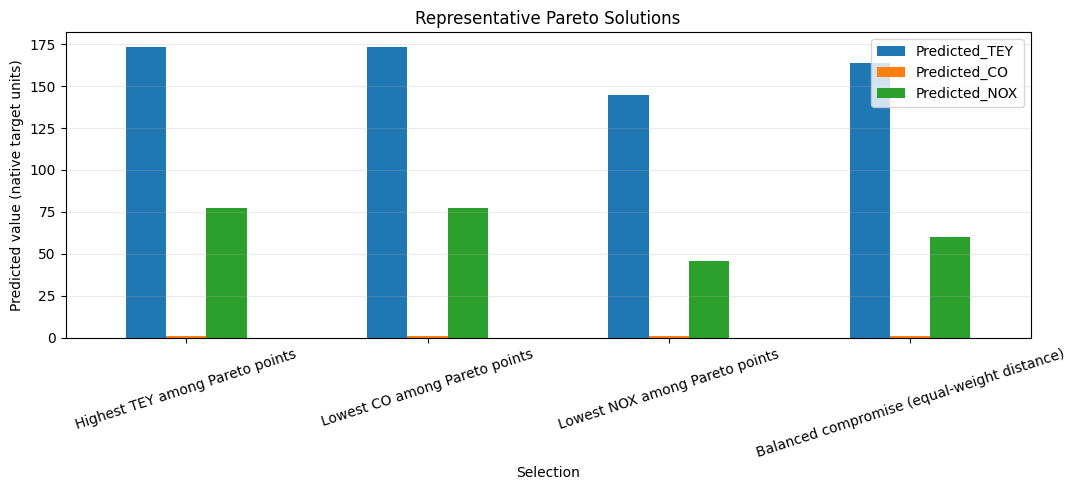

In [9]:
# ============================================================
# 9. REPRESENTATIVE PARETO SOLUTION COMPARISON
# ============================================================

if not representative_solutions.empty:
    objective_columns = [
        "Predicted_TEY", "Predicted_CO", "Predicted_NOX"
    ]
    available_objectives = [
        col for col in objective_columns if col in representative_solutions.columns
    ]

    if available_objectives:
        ax = representative_solutions.set_index("Selection")[available_objectives].plot(
            kind="bar", figsize=(11, 5), rot=18
        )
        ax.set_title("Representative Pareto Solutions")
        ax.set_ylabel("Predicted value (native target units)")
        ax.set_xlabel("Selection")
        ax.grid(axis="y", alpha=0.25)
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "representative_pareto_objectives.png", dpi=200)
        plt.show()

In [10]:
# ============================================================
# 10. FINAL ENGINEERING INTERPRETATION
# ============================================================

final_findings = [
    ("TEY prediction",
     "Random Forest is selected because it achieved the lowest MAE among the compared models."),
    ("CO prediction",
     "Gradient Boosting is selected because it achieved the lowest MAE among the compared models."),
    ("NOX prediction",
     "Linear Regression is selected because it achieved the lowest MAE among the compared models, "
     "but its predictive performance is limited."),
    ("NOX distribution",
     "Mean NOX decreases from approximately 67.58 in 2011 to 59.89 in 2015. "
     "This is an observed year-wise difference, not proof of its cause."),
    ("Operating regimes",
     "K-Means describes historical operating groups. The clusters should not be interpreted "
     "as safe, optimal, or causal regimes."),
    ("Multi-objective optimization",
     "Pareto analysis identifies trade-offs among predicted TEY, CO, and NOX for the evaluated "
     "historical candidate conditions. Pareto optimality is relative to the candidate set and models."),
    ("Model limitations",
     "The models learn observational relationships. Their predictions do not establish causal "
     "effects of changing operating parameters and do not validate turbine setpoints.")
]

findings_df = pd.DataFrame(final_findings, columns=["Area", "Finding"])
findings_df.to_csv(OUTPUT_DIR / "final_engineering_findings.csv", index=False)
display(findings_df)

,Area,Finding
0,TEY prediction,Random Forest is selected because it achieved ...
1,CO prediction,Gradient Boosting is selected because it achie...
2,NOX prediction,Linear Regression is selected because it achie...
3,NOX distribution,Mean NOX decreases from approximately 67.58 in...
4,Operating regimes,K-Means describes historical operating groups....
5,Multi-objective optimization,Pareto analysis identifies trade-offs among pr...
6,Model limitations,The models learn observational relationships. ...


In [11]:
# ============================================================
# 11. PROJECT LIMITATIONS AND REPRODUCIBILITY
# ============================================================

limitations = [
    "The dataset is observational; model relationships are not causal effects.",
    "TEY represents energy yield/output and is not thermal efficiency.",
    "The dataset does not provide the fuel-energy input needed to calculate thermal efficiency.",
    "NOX prediction is weak on the 2015 comparison data (R-squared approximately 0.158).",
    "NOX residual analysis showed systematic overprediction in the 2015 comparison data.",
    "Feature distributions differ across years, especially NOX and TIT.",
    "The 2015 dataset has been examined in prior experiments; it should be called a comparison set, not an untouched test set.",
    "Pareto solutions are model-supported candidates, not experimentally validated or safe operating setpoints.",
    "The optimization explores historical feature combinations and does not demonstrate dynamic process control."
]

limitations_df = pd.DataFrame({"Project limitation": limitations})
limitations_df.to_csv(OUTPUT_DIR / "project_limitations.csv", index=False)
display(limitations_df)

print("\nFinal synthesis completed.")
print("All generated files saved to:", OUTPUT_DIR)

,Project limitation
0,The dataset is observational; model relationsh...
1,TEY represents energy yield/output and is not ...
2,The dataset does not provide the fuel-energy i...
3,NOX prediction is weak on the 2015 comparison ...
4,NOX residual analysis showed systematic overpr...
5,"Feature distributions differ across years, esp..."
6,The 2015 dataset has been examined in prior ex...
7,Pareto solutions are model-supported candidate...
8,The optimization explores historical feature c...



Final synthesis completed.
All generated files saved to: c:\Users\devra\Music\gas-turbine-ml\outputs\final_project_synthesis
